<a href="https://colab.research.google.com/github/Vigneshvar16/NLP_DSA/blob/main/ASSIGNMENT_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


======== DATA ========
reports 1200 | multi-sentence threads 330 | tokens 49183

======== TASK 1 ========
cue-only  P/R/F1: 1.00 1.00 1.00
cue+topic P/R/F1: 1.00 1.00 1.00
boundary kappa (simulated 2nd annotator, 448 gaps): 0.79
reports with a pronoun whose antecedent is in an EARLIER sentence: 27.5%

======== TASK 2 - resolvers (pronoun accuracy, MUC F1, B-cubed F1) ========
recency  acc=0.533 MUC=0.598 B3=0.851
hobbs    acc=0.669 MUC=0.709 B3=0.891
center   acc=0.751 MUC=0.814 B3=0.924
Hobbs-style traces (search order = nearest sentence first, left-to-right; candidates shown with sentence no.):
  report 261: 'it' in S2: order [('the underpass', 0), ('the culvert', 0)] -> chose 'the underpass'
  report 261: 'They' in S3: order [('Locals', 1)] -> chose 'Locals'
  report 279: 'it' in S2: order [('the lane', 0), ('the culvert', 0)] -> chose 'the lane'
  report 279: 'It' in S3: order [('the lane', 0), ('the culvert', 0)] -> chose 'the lane'
  report 274: 'it' in S2: order [('the underpas

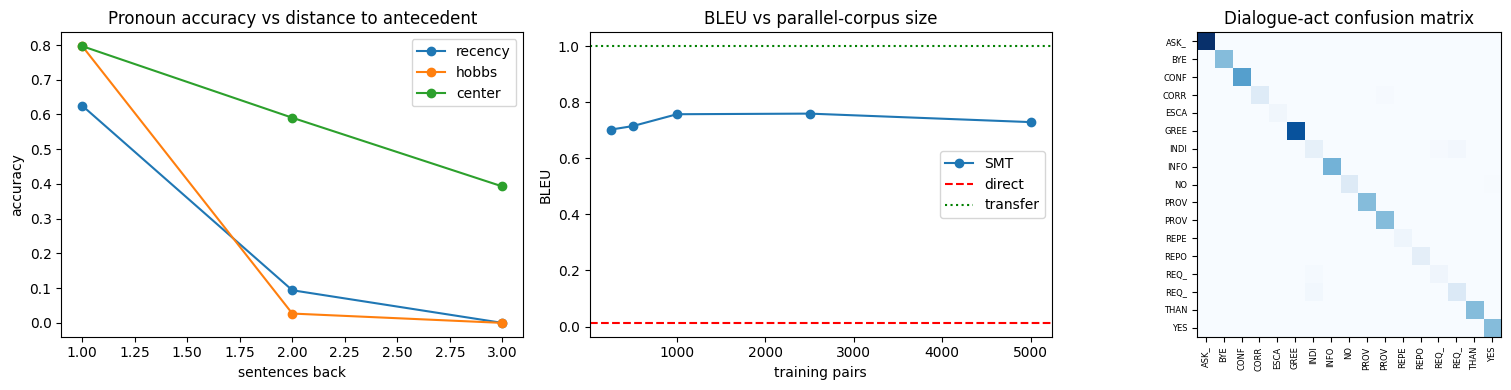

In [1]:
# -*- coding: utf-8 -*-
"""
DSA03 NLP - Assignment 5 (CO5): Discourse-aware public information service
ONE CELL for Google Colab. Needs only: numpy, scipy, scikit-learn, matplotlib (all preinstalled).
No downloads, no API calls, no NLTK data. Runs in ~1-2 minutes. Data is SYNTHETIC (documented below).
"""
import re, random, math, time, tracemalloc, itertools, copy
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, cohen_kappa_score

random.seed(7); np.random.seed(7)
RES = []                                   # Task-10 result table rows
def H(t): print("\n" + "=" * 8, t, "=" * 8)
def run(name, fn, items):
    tracemalloc.start(); t0 = time.perf_counter(); out = fn(); dt = time.perf_counter() - t0
    mem = tracemalloc.get_traced_memory()[1] / 1e6; tracemalloc.stop()
    RES.append((name, items, dt, mem)); return out

# ------------------------------------------------------------------ DATA (synthetic, documented)
NOUNS = ["road", "bridge", "culvert", "lane", "highway", "underpass", "causeway", "bund"]
PLACES = ["Anna Nagar", "Velachery", "Thanjavur", "Kumbakonam", "Tambaram", "Adyar", "Perambur",
          "Medavakkam", "Orathanadu", "Pattukottai"]
TIMES = ["5 am", "6 am", "7 am", "9 am", "noon", "3 pm", "8 pm"]
EID = itertools.count()

def M(w, ent, role, typ, num="sg", an=False):
    return dict(w=w, ent=ent, role=role, typ=typ, num=num, an=an)

def gen_report(rid, multi):
    pool = random.sample(NOUNS, 6); sents = []; noun = {}
    for g in range(random.choice([1, 2, 2, 3]) if multi else 1):
        X, Y = pool[2 * g], pool[2 * g + 1]; P = random.choice(PLACES); T = random.choice(TIMES)
        ex, ey, er = next(EID), next(EID), next(EID); noun[ex], noun[ey] = X, Y
        lead = "Separately, the " if g else "The "
        sents.append(dict(kind="state", seg=g, txt=f"{lead}{X} near the {Y} at {P} has been flooded since {T} and the water level is still rising fast.",
                          m=[M(f"the {X}", ex, "subj", "np"), M(f"the {Y}", ey, "obj", "np")]))
        if not multi: break
        t1 = ex if random.random() < .65 else ey
        sents.append(dict(kind="cond", seg=g, txt=f"Locals say it has been blocked since {T} and no vehicle can pass.",
                          m=[M("Locals", er, "subj", "np", "pl", True), M("it", t1, "subj", "pron")]))
        if random.random() < .8:
            eb, ef = next(EID), next(EID)
            sents.append(dict(kind="people", seg=g, txt="They need boats and food urgently, please send help.",
                              m=[M("They", er, "subj", "pron", "pl", True), M("boats", eb, "obj", "np", "pl"), M("food", ef, "obj", "np")]))
        if random.random() < .7:
            t2 = t1 if random.random() < .7 else (ey if t1 == ex else ex)
            if random.random() < .65:
                sents.append(dict(kind="repair", seg=g, txt="It will need repair after the water goes down.", m=[M("It", t2, "subj", "pron")]))
            else:
                sents.append(dict(kind="repair", seg=g, txt=f"The {noun[t2]} will need repair after the water goes down.", m=[M(f"the {noun[t2]}", t2, "subj", "np")]))
    for i, s in enumerate(sents):
        for j, m in enumerate(s["m"]): m["id"] = (rid, i, j); m["sent"] = i
    return dict(rid=rid, sents=sents, gold_b={i for i in range(1, len(sents)) if sents[i]["seg"] != sents[i - 1]["seg"]})

REPS = [gen_report(i, i < 330) for i in range(1200)]; random.shuffle(REPS)
MULTI = [r for r in REPS if len(r["sents"]) > 1]
tok = lambda t: re.findall(r"\w+", t)
H("DATA"); print("reports", len(REPS), "| multi-sentence threads", len(MULTI),
                  "| tokens", sum(len(tok(s["txt"])) for r in REPS for s in r["sents"]))

# ------------------------------------------------------------------ TASK 1: segmentation + agreement
STOP = set("the a an and is has been since at near it they will after still no can".split())
cw = lambda t: {w for w in re.findall(r"[a-z]+", t.lower()) if w not in STOP}
def segment(rep, overlap=True):
    b = set(); segw = cw(rep["sents"][0]["txt"])
    for i in range(1, len(rep["sents"])):
        t = rep["sents"][i]["txt"].lower(); cue = t.startswith(("separately", "meanwhile", "another"))
        pr = t.startswith(("it ", "they ", "locals say it"))
        if cue or (overlap and not pr and not (cw(t) & segw)): b.add(i); segw = set()
        segw |= cw(t)
    return b
def seg_f1(reps, **kw):
    tp = fp = fn = 0
    for r in reps:
        p = segment(r, **kw); g = r["gold_b"]; tp += len(p & g); fp += len(p - g); fn += len(g - p)
    pr, rc = tp / max(tp + fp, 1), tp / max(tp + fn, 1); return pr, rc, 2 * pr * rc / max(pr + rc, 1e-9)
H("TASK 1")
run("Segmenter", lambda: [segment(r) for r in REPS], len(REPS))
print("cue-only  P/R/F1: %.2f %.2f %.2f" % seg_f1(MULTI, overlap=False))
print("cue+topic P/R/F1: %.2f %.2f %.2f" % seg_f1(MULTI))
dbl = MULTI[:int(.25 * len(MULTI))]; a, b = [], []
for r in dbl:
    for i in range(1, len(r["sents"])):
        x = int(i in r["gold_b"]); a.append(x); b.append(x ^ (random.random() < .06))   # annotator B simulated: 6% disagreement
print("boundary kappa (simulated 2nd annotator, %d gaps): %.2f" % (len(a), cohen_kappa_score(a, b)))
print("reports with a pronoun whose antecedent is in an EARLIER sentence: %.1f%%" %
      (100 * sum(any(m["typ"] == "pron" for s in r["sents"] for m in s["m"]) for r in REPS) / len(REPS)))

# ------------------------------------------------------------------ TASK 2: reference resolution
PR = {"it": ("sg", False), "they": ("pl", True), "adhu": ("sg", False), "avanga": ("pl", True)}
ORIG = {"it", "they"}                                  # original design: English pronouns only
agree = lambda w, c: PR[w.lower()] == (c["num"], c["an"])
head = lambda m: m["w"].lower().split()[-1]
RW = {"subj": 3, "obj": 2}
def resolve(sents, mode, lex=ORIG, log=None, bounds=()):
    """mode: recency | hobbs (nearest sentence, left-to-right, NP candidates only) | center (Cf rank: role + repeated mention - distance)"""
    ment, root, ant = [], {}, {}
    for i, s in enumerate(sents):
        if i in bounds: ment = []                      # discourse segmentation limits the candidate pool
        for m in s["m"]:
            if m["typ"] == "np":
                a = next((x[1] for x in ment if x[0]["typ"] == "np" and head(x[0]) == head(m)), m)   # string match for NPs
                ment.append((m, a, i, len(ment))); root[m["id"]] = a["id"]; continue
            if m["w"].lower() not in lex: root[m["id"]] = m["id"]; ant[m["id"]] = None; continue
            cand = [x for x in ment if agree(m["w"], x[0])]
            if mode == "hobbs": cand = [x for x in cand if x[0]["typ"] == "np"]
            if not cand: root[m["id"]] = m["id"]; ant[m["id"]] = None; continue
            if mode == "recency": best = max(cand, key=lambda x: (x[2], x[3]))
            elif mode == "hobbs":
                cand.sort(key=lambda x: (-x[2], x[3])); best = cand[0]
            else:
                sc = lambda x: RW.get(x[0]["role"], 1) + 2 * sum(1 for y in ment if y[1]["id"] == x[1]["id"]) - .5 * (i - x[2])
                best = max(cand, key=lambda x: (sc(x), x[3]))
            if log is not None: log.append((m["w"], i, [(c[0]["w"], c[2]) for c in cand][:4], best[1]["w"]))
            ment.append((m, best[1], i, len(ment))); root[m["id"]] = best[1]["id"]; ant[m["id"]] = best[1]
    return root, ant

def evaluate(reps, mode):
    ok, tot = Counter(), Counter(); rn = rd = pn = pd = 0; br = bp = N = 0
    for rep in reps:
        root, ant = resolve(rep["sents"], mode, bounds=segment(rep)); ms = [m for s in rep["sents"] for m in s["m"]]
        for m in ms:
            if m["typ"] == "pron":
                d = m["sent"] - max(x["sent"] for x in ms if x["ent"] == m["ent"] and x["sent"] < m["sent"])
                tot[d] += 1; ok[d] += bool(ant[m["id"]] and ant[m["id"]]["ent"] == m["ent"])
        g, p = defaultdict(set), defaultdict(set)
        for m in ms: g[m["ent"]].add(m["id"]); p[root[m["id"]]].add(m["id"])
        gid = {m["id"]: m["ent"] for m in ms}; pid = {m["id"]: root[m["id"]] for m in ms}
        for c in g.values(): rn += len(c) - len({pid[x] for x in c}); rd += len(c) - 1
        for c in p.values(): pn += len(c) - len({gid[x] for x in c}); pd += len(c) - 1
        for m in ms:
            gc, pc = g[gid[m["id"]]], p[pid[m["id"]]]; inter = len(gc & pc); br += inter / len(gc); bp += inter / len(pc); N += 1
    mr, mp = rn / max(rd, 1), pn / max(pd, 1); b3r, b3p = br / N, bp / N
    f = lambda p, r: 2 * p * r / max(p + r, 1e-9)
    return dict(acc=sum(ok.values()) / sum(tot.values()), muc=f(mp, mr), b3=f(b3p, b3r), dist={d: ok[d] / tot[d] for d in sorted(tot)})

H("TASK 2 - resolvers (pronoun accuracy, MUC F1, B-cubed F1)")
EV = {}
for mode in ["recency", "hobbs", "center"]:
    EV[mode] = run("Resolver-" + mode, lambda: evaluate(MULTI, mode), len(MULTI))
    e = EV[mode]; print("%-8s acc=%.3f MUC=%.3f B3=%.3f" % (mode, e["acc"], e["muc"], e["b3"]))
print("Hobbs-style traces (search order = nearest sentence first, left-to-right; candidates shown with sentence no.):")
for r in MULTI[:3]:
    lg = []; resolve(r["sents"], "hobbs", log=lg, bounds=segment(r))
    for w, i, c, ch in lg[:2]: print(f"  report {r['rid']}: '{w}' in S{i+1}: order {c} -> chose '{ch}'")

def transitions(rep):
    cf = [[m["ent"] for m in sorted(s["m"], key=lambda m: {"subj": 0, "obj": 1}.get(m["role"], 2))] for s in rep["sents"]]
    out, cb_prev = [], None
    for i in range(1, len(cf)):
        cb = next((e for e in cf[i - 1] if e in cf[i]), None); cp = cf[i][0] if cf[i] else None
        t = "Shift" if cb is None else ("Continue" if (cb == cb_prev or cb_prev is None) and cb == cp else "Retain" if (cb == cb_prev or cb_prev is None) else "Shift")
        out.append(t); cb_prev = cb
    return out
print("Centering transitions:", [transitions(r) for r in MULTI[:3]])

# ------------------------------------------------------------------ TASK 3: coherence
H("TASK 3 - cohesion counts + entity grid")
txt = " ".join(s["txt"] for r in MULTI for s in r["sents"]).lower()
print("reference(pronouns):", len(re.findall(r"\b(it|they)\b", txt)), "| conjunction:", len(re.findall(r"\b(and|since|after|separately)\b", txt)),
      "| lexical repetition (def. NPs):", len(re.findall(r"\bthe (road|bridge|culvert|lane|highway|underpass|causeway|bund)\b", txt)),
      "| ellipsis: 0 | substitution: 0 (none in this synthetic data)")
def grid(sent_roles):
    T = Counter()
    for e in {e for s in sent_roles for e in s}:
        col = [s.get(e, "-") for s in sent_roles]
        for x, y in zip(col, col[1:]): T[x + y] += 1
    n = sum(T.values()) - T["--"]; cont = sum(v for k, v in T.items() if "-" not in k)
    return cont / max(n, 1), {k: round(v / max(sum(T.values()), 1), 2) for k, v in T.most_common(4)}
roles = lambda r: [{m["ent"]: {"subj": "S", "obj": "O"}[m["role"]] for m in s["m"]} for s in r["sents"]]
print("entity-grid transition distribution, first 3 threads:", [grid(roles(r))[1] for r in MULTI[:3]])
sc_o = [grid(roles(r))[0] for r in MULTI[:100]]
sc_s = []
for r in MULTI[:100]:
    ro = roles(r); random.shuffle(ro); sc_s.append(grid(ro)[0])
print("coherence score original %.2f vs sentences shuffled %.2f (proxy validation; replace by reader ranking below)" % (np.mean(sc_o), np.mean(sc_s)))
HUMAN_RANK = None    # <- paste 10 reader ranks here to get Spearman against BULLETIN_SCORES printed in Task 8

# ------------------------------------------------------------------ TASK 4: RST
H("TASK 4 - RST trees")
REL = {"cond": "Elaboration", "people": "Result", "repair": "Elaboration"}
def rst(rep):
    segs = defaultdict(list)
    for i, s in enumerate(rep["sents"]): segs[s["seg"]].append(i)
    ts = []
    for ids in segs.values():
        t = ids[0]
        for i in ids[1:]: t = (REL[rep["sents"][i]["kind"]], t, i)       # (relation, nucleus, satellite)
        ts.append(t)
    t = ts[0]
    for u in ts[1:]: t = ("List", t, u)                                   # multinuclear
    return t
nuc = lambda t: [t] if isinstance(t, int) else nuc(t[1]) + (nuc(t[2]) if t[0] == "List" else [])
nodes = lambda t: [] if isinstance(t, int) else [t[0]] + nodes(t[1]) + nodes(t[2])
r0 = next(r for r in MULTI if len(r["sents"]) >= 4)
print("tree:", rst(r0)); print("nucleus-only summary:", " ".join(r0["sents"][i]["txt"] for i in nuc(rst(r0))))
rels = [x for r in MULTI[:60] for x in nodes(rst(r))]; nuclr = ["NN" if x == "List" else "NS" for x in rels]
rb = [x if random.random() > .20 else random.choice(["Elaboration", "Result", "List"]) for x in rels]
nb = [x if random.random() > .07 else random.choice(["NN", "NS"]) for x in nuclr]
print("kappa relation labels %.2f | kappa nuclearity %.2f (simulated 2nd annotator)" % (cohen_kappa_score(rels, rb), cohen_kappa_score(nuclr, nb)))
print("Flat reading: S_n follows S_n-1. Tree: 'repair' attaches to the whole segment, 'Separately' starts a new List item -> flat cannot show attachment height or which span is central.")

# ------------------------------------------------------------------ TASK 5: dialogue managers
H("TASK 5 - frame dialogue manager traces")
ORDER = ["location", "people", "transport", "medical"]
ASK = {"location": "Which area are you in?", "people": "How many people are with you?", "transport": "Do you need transport?", "medical": "Anyone injured or needing medical help?"}
def nlu(u):
    f, l = {}, u.lower()
    for p in PLACES:
        if p.lower() in l: f["location"] = p
    m = re.search(r"(\d+)\s*(people|persons|of us|members)|we are (\d+)", l)
    if m: f["people"] = int(m.group(1) or m.group(3))
    if re.search(r"(need|want).{0,12}(vehicle|transport|bus)", l): f["transport"] = True
    elif re.search(r"(no|don't need).{0,10}(vehicle|transport)|have (a|my) (car|vehicle)", l): f["transport"] = False
    if re.search(r"injur|medical|doctor|insulin|pregnan", l): f["medical"] = not re.search(r"no medical|no injur", l)
    return f, bool(re.search(r"sorry|i meant|i said", l)), bool(re.search(r"\bcancel\b|never mind", l))
def dm_run(turns, verbose=True):
    st = {k: None for k in ORDER}; asked = None
    for u in turns:
        f, corr, cancel = nlu(u); l = u.lower().strip()
        if cancel:
            if verbose: print(f"  U: {u:55s} -> CANCELLED"); return "CANCELLED"
        if asked and asked not in f:
            if asked == "people" and re.fullmatch(r"\D*(\d+)\D*", l): f["people"] = int(re.findall(r"\d+", l)[0])
            elif asked in ("transport", "medical") and re.match(r"(yes|yeah)", l): f[asked] = True
            elif asked in ("transport", "medical") and re.match(r"no", l): f[asked] = False
        changed = [k for k, v in f.items() if st[k] not in (None, v)]; st.update(f)
        miss = [k for k in ORDER if st[k] is None]
        if miss: asked = miss[0]; rep = ASK[asked]
        else: asked = None; rep = f"To confirm: {st['people']} people at {st['location']}. Nearest open camp: Govt School Camp, {st['location']}."
        if verbose: print(f"  U: {u:55s} state={st} {'CORRECTED '+str(changed) if changed else ''}\n     S: {rep}")
    return st
print(" normal"); dm_run(["Where is the nearest relief camp? I am in Adyar", "4", "yes", "no medical problem"])
print(" over-answer"); dm_run(["We are 5 people at Velachery and need a vehicle, one is injured"])
print(" correction"); dm_run(["Adyar, 3 people", "sorry I meant Tambaram", "no vehicle needed", "no injuries"])
FSM = {("START", "any"): "ASK_LOC", ("ASK_LOC", "place"): "ASK_PEOPLE", ("ASK_PEOPLE", "number"): "CONFIRM", ("CONFIRM", "yes"): "DONE (final)", ("CONFIRM", "no"): "ASK_LOC"}
print(" FSM transitions (+ any state --cancel--> CANCELLED):", FSM)

# ------------------------------------------------------------------ TASK 6: dialogue acts
H("TASK 6 - dialogue acts")
TPL = {"GREET": ["hello", "hi is this the control room", "good morning", "vanakkam"],
       "REQ_SHELTER": ["where is the nearest relief camp", "i need a shelter for my family", "which camp can we go to", "tell me the relief camp address"],
       "REQ_ROAD": ["is the {R} road open", "which roads are closed near {P}", "what is the road status at {P}"],
       "REPORT_INCIDENT": ["water is entering our houses at {P}", "a tree has fallen on the {R} road", "the power line is down near {P}"],
       "INDIRECT_REQ": ["do you know if the camp at {P} is open", "can you tell me if the {R} road is open", "could you check whether there is a shelter near {P}", "i was wondering if buses are running from {P}"],
       "PROVIDE_LOC": ["{P}", "we are at {P}", "near {P}", "{P} area"], "PROVIDE_NUM": ["{n}", "we are {n} people", "{n} of us", "{n} people"],
       "YES": ["yes", "yes please", "correct", "yeah that is right"], "NO": ["no", "no that is wrong", "not that one"],
       "CORRECT": ["sorry i meant {P}", "no i said {P}", "not that, {P}"], "REPEAT_REQ": ["can you repeat that", "say it again please", "sorry what"],
       "THANKS": ["thank you", "thanks a lot", "ok thanks"], "BYE": ["bye", "goodbye", "ok bye"], "ESCALATE": ["let me talk to a person", "connect me to an officer", "i want a human"],
       "ASK_SLOT": ["which area are you in", "how many people are with you", "do you need transport"],
       "INFORM": ["the nearest open camp is the government school at {P}", "the {R} road is closed due to flooding"],
       "CONFIRM_Q": ["you are at {P} is that correct", "so {n} people right"]}
ACTS = list(TPL); print(len(ACTS), "acts:", ACTS)
SIB = {"INDIRECT_REQ": "REQ_SHELTER", "REQ_SHELTER": "INDIRECT_REQ", "REQ_ROAD": "INDIRECT_REQ", "PROVIDE_LOC": "CORRECT", "CORRECT": "PROVIDE_LOC", "YES": "THANKS", "NO": "CORRECT", "PROVIDE_NUM": "CONFIRM_Q", "CONFIRM_Q": "PROVIDE_NUM"}
def utt(a):                                     # 15% of utterances borrow a sibling act's wording (indirect/ambiguous), 10% of words dropped
    src = SIB[a] if a in SIB and random.random() < .15 else a
    u = random.choice(TPL[src]).format(P=random.choice(PLACES).lower(), R=random.choice(NOUNS), n=random.randint(2, 9)).split()
    return " ".join(w for w in u if random.random() > .1 or len(u) < 3)
def gen_dialogue():
    d = [("caller", "GREET"), ("agent", "GREET"), ("caller", random.choice(["REQ_SHELTER", "REQ_SHELTER", "REQ_ROAD", "REPORT_INCIDENT", "INDIRECT_REQ", "INDIRECT_REQ"])), ("agent", "ASK_SLOT"), ("caller", "PROVIDE_LOC")]
    if random.random() < .3: d += [("agent", "CONFIRM_Q"), ("caller", "NO"), ("agent", "ASK_SLOT"), ("caller", "CORRECT")]
    if random.random() < .15: d += [("agent", "INFORM"), ("caller", "REPEAT_REQ")]
    d += [("agent", "ASK_SLOT"), ("caller", "PROVIDE_NUM"), ("agent", "CONFIRM_Q"), ("caller", "YES"), ("agent", "INFORM")]
    if random.random() < .1: d += [("caller", "ESCALATE")]
    return d + [("caller", "THANKS"), ("agent", "BYE")]
DLG = [[(sp, a, utt(a)) for sp, a in gen_dialogue()] for _ in range(300)]
def feats(dl):
    rows = []
    for d in dl:
        for i, (sp, a, u) in enumerate(d): rows.append((u, ACTS.index(d[i - 1][1]) if i else -1, min(i, 12) / 12, sp == "agent", a))
    return rows
tr, te = feats(DLG[:200]), feats(DLG[200:])
vec = TfidfVectorizer(ngram_range=(1, 2)).fit([r[0] for r in tr])
def X(rows):
    d = np.zeros((len(rows), len(ACTS) + 2))
    for k, r in enumerate(rows):
        if r[1] >= 0: d[k, r[1]] = 1
        d[k, -2], d[k, -1] = r[2], r[3]
    return hstack([vec.transform([r[0] for r in rows]), csr_matrix(d)]).tocsr()
clf = run("Act classifier", lambda: LogisticRegression(max_iter=2000, C=5).fit(X(tr), [r[4] for r in tr]), len(tr))
P = clf.predict_proba(X(te)); pred = clf.classes_[P.argmax(1)]; yt = [r[4] for r in te]
print("tag distribution (100 test dialogues):", Counter(yt).most_common(5), "...")
gold_b = [y if random.random() > .05 else random.choice(ACTS) for y in yt]       # simulated 2nd annotator
print("annotator agreement: raw %.1f%%  kappa %.2f (simulated)" % (100 * np.mean(np.array(yt) == np.array(gold_b)), cohen_kappa_score(yt, gold_b)))
ACC6 = accuracy_score(yt, pred); print("accuracy %.3f" % ACC6); print(classification_report(yt, pred, zero_division=0, digits=2))
CM = confusion_matrix(yt, pred, labels=clf.classes_)
off = sorted(((CM[i, j], clf.classes_[i], clf.classes_[j]) for i in range(len(CM)) for j in range(len(CM)) if i != j), reverse=True)[:2]
print("two most confused pairs (count, true, predicted):", off)
unc = (P.max(1) < .6).mean(); print("policy: if max prob < 0.6 ask a clarifying question (%.1f%% of turns) instead of acting" % (100 * unc))
print("indirect-speech examples:", [r[0] for r in tr if r[4] == "INDIRECT_REQ"][:5])

# ------------------------------------------------------------------ TASKS 7-8: generation
H("TASKS 7-8 - generation")
ROADS = ["Mount Road", "Lake View Road", "Station Road", "Canal Bank Road", "Temple Street", "Market Road", "Airport Road", "Bypass Road"]
HAZ = ["flooding", "landslide", "fallen tree", "waterlogging"]; COUNT = {"landslide", "fallen tree"}; SEV = {1: "minor", 2: "heavy", 3: "severe"}
def make_inc(i, road):
    return dict(id=i, road=road, area=random.choice(PLACES), hazard=random.choice(HAZ), severity=random.choice([1, 2, 3]), status=random.choice(["closed", "closed", "slow", "reopen"]),
                since=random.choice(TIMES), depth_cm=random.choice([10, 25, 45, 60, 90]), alt_route=random.choice([r for r in ROADS if r != road]),
                shelter=random.choice(["Govt School", "Community Hall", "Panchayat Office"]) + " " + random.choice(PLACES), shelter_cap=random.choice([100, 150, 200, 300]),
                contact="044-" + str(random.randint(2000000, 2999999)), people_affected=random.choice([0, 1, 12, 40, 250]), source=random.choice(["caller", "field team", "police"]),
                updated_at=random.choice(["06:00", "08:00", "10:00", "12:00"]))
DB = [[make_inc(3 * k + j, r) for j, r in enumerate(random.sample(ROADS, 3))] for k in range(40)]    # 40 bulletins x 3 incidents, 15 fields
def select(inc, aud):
    f = [("state", "always")]
    if aud == "field": f.append(("depth", "field needs depth"))
    if inc["severity"] >= 2: f.append(("alt", "severity>=2 -> diversion"))
    if inc["status"] == "closed": f.append(("review", "closed -> review time"))
    if inc["people_affected"] > 0: f.append(("shelter", "people affected>0"))
    if aud == "field": f.append(("contact", "field needs contact"))
    return f
RELG = dict(state=None, depth="Elaboration", alt="Advice", review="Elaboration", shelter="Result", contact="Elaboration")
art = lambda w: "an" if w[0].lower() in "aeiou" else "a"
def np_(head_, mods):
    rank = {"quantity": 0, "opinion": 1, "size": 2, "age": 3, "material": 4}
    return " ".join([m for m, _ in sorted(mods, key=lambda x: rank[x[1]])] + [head_])
def refexp(ent, st):
    if ent["id"] not in st["seen"]: st["seen"].add(ent["id"]); return f"the {ent['road']} at {ent['area']}", "first mention: full definite NP"
    if st["last"] == [ent["id"]]: return "it", "pronoun: only salient inanimate in previous sentence"
    return f"the {ent['road'].split()[-1].lower()}", "short NP: a pronoun would be ambiguous"
def cap(s): return s[0].upper() + s[1:]
def build(incs, aud, naive=False, order=None):
    st = dict(seen=set(), last=[]); sents, rules, plan = [], [], []
    incs = sorted(incs, key=lambda i: (-i["severity"], i["status"] != "closed"))
    for k, inc in enumerate(incs):
        facts = [f for f, _ in select(inc, aud)]; plan.append([(f, RELG[f]) for f in facts])
        mods = [(SEV[inc["severity"]], "opinion")] + ([("large", "size")] if inc["severity"] == 3 else [])
        cause = (art(mods[0][0]) + " " + np_(inc["hazard"], mods)) if inc["hazard"] in COUNT else np_(inc["hazard"], mods[:1])
        conn = "" if k == 0 else ("By contrast, " if incs[k - 1]["status"] != inc["status"] else "Also, ")
        for f in facts:
            ref, why = refexp(inc, st)
            if naive and ref.startswith("the") and ref[4:] in inc["road"].lower(): ref, why = "it", "NAIVE pronoun"
            if f == "state":
                if aud == "field": body = f"{ref} closed since {inc['since']}: {inc['hazard']}" if inc["status"] == "closed" else f"{ref} {inc['status']}: {inc['hazard']}"
                elif inc["status"] == "closed": body = f"{ref} has been closed since {inc['since']} because of {cause}"
                elif inc["status"] == "slow": body = f"{ref} remains open, but traffic is slow because of {cause}"
                else: body = f"{ref} is expected to reopen at {inc['since']} after {cause}"
                ents = [inc["id"]]
            elif f == "depth": body = f"the water on {ref} is {inc['depth_cm']} cm deep"; ents = [inc["id"]]
            elif f == "alt": body = f"traffic is diverted from {ref} via {inc['alt_route']}"; ents = [inc["id"], "alt%d" % inc["id"]]
            elif f == "review": body = f"{ref} will be reviewed at {inc['updated_at']}"; ents = [inc["id"]]
            elif f == "shelter":
                n = inc["people_affected"]; body = f"{n} {'person is' if n == 1 else 'people are'} sheltering at {inc['shelter']}, which can hold {inc['shelter_cap']}"; ents = ["sh%d" % inc["id"]]
            else: body = f"field contact is {inc['contact']}"; ents = ["ct%d" % inc["id"]]
            if f == "state" and conn: body = conn + body[0].lower() + body[1:] if not body.startswith("It") else conn + body
            else: body = cap(body)
            st["last"] = ents if f != "state" else [inc["id"]]
            if f == "alt": st["last"] = [inc["id"], "alt%d" % inc["id"]]
            sents.append((body + ".", {e: ("S" if i == 0 else "O") for i, e in enumerate(ents)})); rules.append((ref, why))
    if order: sents = [sents[i] for i in order]
    return " ".join(s for s, _ in sents), [r for _, r in sents], rules, plan
b0 = DB[0]; txt_n, rl_n, rules, plan = build(b0, "newspaper"); txt_f = build(b0, "field")[0]
print("CONTENT SELECTION (newspaper): included", [f for f, _ in select(b0[0], "newspaper")], "| suppressed: depth_cm, contact, source, updated_at(header)")
print("DISCOURSE PLAN (inc 1):", plan[0]); print("NEWSPAPER:", txt_n); print("FIELD   :", txt_f)
print("Referring-expression decisions:", rules[:6])
print("Pronoun-ambiguity case -> naive:", build(b0, "newspaper", naive=True)[0][:260], "\n   -> ours   :", txt_n[:260])
print("Audience change: content selection + realiser wording changed; discourse plan order unchanged.")
bad = build(b0, "newspaper", order=[3, 2, 1, 0] + list(range(4, len(rl_n)))); print("ORDER FAULT:", bad[0][:220], "\n  stage at fault: DISCOURSE PLANNING (sentences are correct, plan order is wrong).")
def human(incs):
    out = []
    for inc in sorted(incs, key=lambda i: (-i["severity"], i["status"] != "closed")):
        c = random.choice(["due to", "because of"]); v = random.choice(["closed", "shut"])
        out.append(f"The {inc['road']} at {inc['area']} has been {v} since {inc['since']} {c} {SEV[inc['severity']]} {inc['hazard']}." if inc["status"] == "closed" else
                   f"The {inc['road']} at {inc['area']} remains open but slow due to {SEV[inc['severity']]} {inc['hazard']}." if inc["status"] == "slow" else
                   f"The {inc['road']} at {inc['area']} is expected to reopen at {inc['since']}.")
        if inc["severity"] >= 2: out.append(f"Traffic is being {random.choice(['diverted', 'rerouted'])} via {inc['alt_route']}.")
        if inc["people_affected"] > 0: out.append(f"{inc['people_affected']} people are sheltering at {inc['shelter']}.")
    return " ".join(out)
def bleu(refs, hyps, N=4):
    clip, tot, rl, hl = [0] * N, [0] * N, 0, 0
    for r, h in zip(refs, hyps):
        r, h = r.lower().split(), h.lower().split(); rl += len(r); hl += len(h)
        for n in range(1, N + 1):
            rc = Counter(tuple(r[i:i + n]) for i in range(len(r) - n + 1)); hc = Counter(tuple(h[i:i + n]) for i in range(len(h) - n + 1))
            clip[n - 1] += sum(min(v, rc[k]) for k, v in hc.items()); tot[n - 1] += sum(hc.values())
    p = [(clip[i] + (i > 0)) / (tot[i] + (i > 0)) for i in range(N)]
    return (1 if hl > rl else math.exp(1 - rl / max(hl, 1))) * math.exp(sum(math.log(max(x, 1e-9)) for x in p) / N)
GEN = run("Generator", lambda: [build(b, "newspaper") for b in DB], len(DB))
print("BLEU vs synthetic human references (40 bulletins): %.3f" % bleu([human(b) for b in DB], [g[0] for g in GEN]))
gram = sum(len(re.findall(r"\ba [aeiou]|\ban [^aeiou\W]|\b(\w+) \1\b", g[0].lower())) for g in GEN); print("automatic grammar errors (a/an, duplicates):", gram)
BULLETIN_SCORES = [round(grid([r for r in build(b, "newspaper")[1]])[0], 2) for b in DB[:10]]; print("entity-grid scores of 10 bulletins (rank readers' order against these):", BULLETIN_SCORES)
print("generator coherence (mean grid): original order %.2f | shuffled sentences %.2f" % (np.mean([grid(g[1])[0] for g in GEN]), np.mean([grid(random.sample(g[1], len(g[1])))[0] for g in GEN])))
print("HUMAN fluency/adequacy: collect 1-5 ratings from 3 readers for 20 bulletins and paste mean here -> compare with BLEU (not automatable).")

# ------------------------------------------------------------------ TASK 9: machine translation
H("TASK 9 - MT (synthetic verb-final pseudo-language stands in for Tamil/Hindi; plug real pairs into PAIRS)")
NMT = NOUNS + ["shelter", "school"]; ADJ = ["flooded", "closed", "blocked", "unsafe", "open", "damaged"]
PL = [p.replace(" ", "_") for p in PLACES]; UNSEEN = ["Nagapattinam", "Chengalpattu"]; TM = [t.replace(" ", "_") for t in TIMES]
FW = ["the", "near", "at", "is", "has", "been", "since", "please", "avoid", "will", "reopen"]
LEX = {w: w[::-1] + "u" for w in FW + NMT + ADJ}; L = lambda w: LEX.get(w, w)
PATS = [("A", r"the (\w+) near (\S+) is (\w+)$", lambda g: (g[0], g[1], g[2], None)), ("B", r"(\w+) at (\S+) has been (\w+) since (\S+)$", lambda g: (g[0], g[1], g[2], g[3])),
        ("C", r"please avoid the (\w+) near (\S+)$", lambda g: (g[0], g[1], None, None)), ("E", r"(\w+) will reopen at (\S+)$", lambda g: (g[0], None, None, g[1]))]
ORD = {"A": lambda n, p, a, t: ["the", n, p, "near", a, "is"], "B": lambda n, p, a, t: [n, p, "at", t, "since", a, "has", "been"],
       "C": lambda n, p, a, t: ["please", "the", n, p, "near", "avoid"], "E": lambda n, p, a, t: [n, t, "at", "reopen", "will"]}
def analyse(s):
    for k, pat, f in PATS:
        m = re.match(pat, s)
        if m: return k, f(m.groups())
def transfer(s):                                         # analysis -> structural transfer (explicit rules in ORD) -> lexical transfer
    k, sl = analyse(s); return [L(w) for w in ORD[k](*sl)]
IL = {"A": ("STATE", "PRES"), "B": ("STATE", "PERFECT"), "C": ("REQUEST_AVOID", "IMP"), "E": ("EVENT_REOPEN", "FUT")}
def interlingua(s):                                      # source -> language-neutral frame -> target generation from frame only
    k, (n, p, a, t) = analyse(s); frame = dict(sem=IL[k][0], tense=IL[k][1], theme=n, loc=p, attr=a, time=t, _k=k); return frame
def gen_from_frame(fr): return [L(w) for w in ORD[fr["_k"]](fr["theme"], fr["loc"], fr["attr"], fr["time"])]
def gen_en(places):
    k = random.choice("ABCE"); n = random.choice(NMT); p = random.choice(places); a = random.choice(ADJ); t = random.choice(TM)
    return {"A": f"the {n} near {p} is {a}", "B": f"{n} at {p} has been {a} since {t}", "C": f"please avoid the {n} near {p}", "E": f"{n} will reopen at {t}"}[k]
PAIRS = [(s, transfer(s)) for s in (gen_en(PL) for _ in range(5000))]
TEST = [(s, transfer(s)) for s in (gen_en(PL + UNSEEN * 2) for _ in range(300))]
print("train pairs", len(PAIRS), "| held-out", len(TEST), "| components for n=2,3,8 languages: direct", [n * (n - 1) for n in (2, 3, 8)],
      "transfer", [2 * n + n * (n - 1) for n in (2, 3, 8)], "interlingua", [2 * n for n in (2, 3, 8)])
print("interlingua frames:", interlingua("the road near Adyar is flooded"), "|", interlingua("bund at Adyar has been closed since 6_am"))
print("Forced distinction: English 'is flooded/closed' leaves state-vs-event open; the frame must choose STATE vs PERFECT aspect (target verb forms differ).")
def ibm1(pairs, iters):
    fv = {f for _, F in pairs for f in F}; t = defaultdict(lambda: 1 / len(fv))
    for _ in range(iters):
        cnt, tot = defaultdict(float), defaultdict(float)
        for E, F in pairs:
            for f in F:
                z = sum(t[(f, e)] for e in E)
                for e in E: c = t[(f, e)] / z; cnt[(f, e)] += c; tot[e] += c
        for (f, e), c in cnt.items(): t[(f, e)] = c / tot[e]
    return t
def train_smt(pairs):
    pp = [(s.split(), f) for s, f in pairs]; t = ibm1(pp, 4); cand = defaultdict(list)
    for (f, e), p in t.items(): cand[e].append((p, f))
    cand = {e: [(f, p) for p, f in sorted(v, reverse=True)[:2]] for e, v in cand.items()}
    bi, uni, V = Counter(), Counter(), len({w for _, f in pp for w in f}) + 1
    for _, f in pp:
        seq = ["<s>"] + f
        for x, y in zip(seq, seq[1:]): bi[(x, y)] += 1; uni[x] += 1
    lm = lambda x, y: math.log((bi[(x, y)] + .1) / (uni[x] + .1 * V))
    return cand, lm
def decode(src, cand, lm, beam=10):
    src = src.split(); n = len(src); states = [(0., (), ())]
    for _ in range(n):
        new = []
        for sc, used, seq in states:
            last = seq[-1] if seq else "<s>"
            for i in range(n):
                if i in used: continue
                for f, p in cand.get(src[i], [(src[i], 1.0)]): new.append((sc + math.log(p) + lm(last, f), used + (i,), seq + (f,)))
        states = sorted(new, key=lambda x: -x[0])[:beam]
    return list(states[0][2]), states[0][0] / n
cand, lm = run("SMT-train(IBM1+bigram)", lambda: train_smt(PAIRS), len(PAIRS))
best = {e: v[0][0] for e, v in cand.items()}
direct = lambda s: [best.get(w, w) for w in s.split()]
bl = lambda fn: bleu([" ".join(r) for _, r in TEST], [" ".join(fn(s)) for s, _ in TEST])
B = dict(direct=run("MT-direct", lambda: bl(direct), 300), transfer=run("MT-transfer", lambda: bl(transfer), 300),
         interlingua=run("MT-interlingua", lambda: bl(lambda s: gen_from_frame(interlingua(s))), 300), smt=run("MT-SMT", lambda: bl(lambda s: decode(s, cand, lm)[0]), 300))
print("BLEU on held-out:", {k: round(v, 3) for k, v in B.items()}); print("(references are rule-made stand-ins -> rule systems score ~1.0; use real parallel data + human adequacy/fluency ratings before trusting this.)")
SIZES = [250, 500, 1000, 2500, 5000]; SB = []
for n in SIZES:
    c, l = train_smt(PAIRS[:n]); SB.append(bleu([" ".join(r) for _, r in TEST], [" ".join(decode(s, c, l)[0]) for s, _ in TEST]))
print("SMT BLEU vs corpus size", dict(zip(SIZES, np.round(SB, 3))))

# ------------------------------------------------------------------ TASK 10: tests
H("TASK 10 - tests against hand calculations")
mk = lambda *ms: [dict(m, id=("t", k, j), sent=k) for k, s in enumerate(ms) for j, m in enumerate(s)]
def mini(): return [dict(m=[dict(M("the road", 1, "subj", "np"), id=("t", 0, 0)), dict(M("the bridge", 2, "obj", "np"), id=("t", 0, 1))]), dict(m=[dict(M("It", 1, "subj", "pron"), id=("t", 1, 0))])]
assert resolve(mini(), "hobbs", bounds=())[1][("t", 1, 0)]["w"] == "the road"                    # Hobbs hand trace: S1 left-to-right, 'the road' first agreeing NP
assert transitions(dict(sents=[dict(m=[M("a", 1, "subj", "np")]), dict(m=[M("a", 1, "subj", "np")]), dict(m=[M("b", 2, "subj", "np")])])) == ["Continue", "Shift"]
rep = dict(sents=[dict(kind=k, seg=0, m=[]) for k in ["state", "cond", "people", "repair"]]); assert rst(rep) == ("Elaboration", ("Result", ("Elaboration", 0, 1), 2), 3)
assert dm_run(["We are 4 people at Velachery"], False)["people"] == 4 and dm_run(["Adyar", "sorry I meant Tambaram"], False)["location"] == "Tambaram"
t = ibm1([(["big", "house"], ["casa", "grande"]), (["house"], ["casa"])], 1)
assert abs(t[("casa", "house")] - .75) < 1e-9 and abs(t[("grande", "house")] - .25) < 1e-9 and abs(t[("casa", "big")] - .5) < 1e-9
print("All hand-calculation tests passed (Hobbs, centering, RST tree, slot trace, IBM-1 EM iteration).")
print("\n%-26s %8s %9s %9s" % ("component", "items", "time(s)", "peakMB"))
for n, i, dt, mem in RES: print("%-26s %8d %9.2f %9.1f" % (n, i, dt, mem))

# ------------------------------------------------------------------ TASK 12: Day-4 multi-party / code-mixed / noisy
H("TASK 12 - re-evaluation on multi-party, code-mixed, ASR-noisy input")
NP_RE = re.compile(r"\b(?:the |andha )?(?:(?:%s) )?(?:%s)\b|\b(?:locals|families|residents)\b" % ("|".join(PLACES), "|".join(NOUNS)), re.I)
def parse_text(text, k, garble=None):
    ms = []
    for j, m in enumerate(NP_RE.finditer(text)):
        pl = m.group(0).lower() in ("locals", "families", "residents"); ms.append(dict(M(m.group(0), None, "subj" if j == 0 else "obj", "np", "pl" if pl else "sg", pl), id=(k, j)))
    for w in re.findall(r"\w+", text):
        if w.lower() in PR or (garble and w in garble): ms.append(dict(M(w, None, "subj", "pron"), id=(k, 90 + len(ms)), conf=(garble or {}).get(w, 1.0)))
    return dict(txt=text, m=ms)
def trace(msgs, title, garble=None, lex=ORIG, split=False):
    print(" ", title)
    sents = [parse_text(t, k, garble) for k, (sp, t) in enumerate(msgs)]
    if split:                                         # speaker-aware: pronoun-only message joins the same speaker's latest thread
        keep = []
        for k, (sp, t) in enumerate(msgs):
            keep.append(sents[k]) if not any(m["typ"] == "pron" for m in sents[k]["m"]) or True else None
    for mode in ["recency", "hobbs", "center"]:
        lg = []; ss = copy.deepcopy(sents)
        if split:                                     # restrict candidate pool to the speaker's own thread
            for k, (sp, t) in enumerate(msgs):
                if any(m["typ"] == "pron" for m in ss[k]["m"]):
                    own = [s for j, s in enumerate(ss[:k]) if msgs[j][0] == sp]; ss_k = own + [ss[k]]
                    lg2 = []; _, an = resolve(ss_k, mode, PR, lg2); lg += lg2
        else: resolve(ss, mode, lex, lg)
        res = [(w, ch) for w, i, c, ch in lg]; unresolved = [m["w"] for s in ss for m in s["m"] if m["typ"] == "pron" and not any(m["w"] == w for w, _ in res)]
        print(f"     {mode:8s} resolved={res} unresolved(not in lexicon / no candidate)={unresolved}")
print("original design (flat stream, English pronoun lexicon):")
trace([("Ravi", "The road near the bridge at Adyar is flooded."), ("Meena", "Velachery culvert is blocked too."), ("Ravi", "It has been closed since 6 am.")], "1) multi-party: 'It' (Ravi) should be the Adyar road; flat resolver prefers the nearer culvert")
trace([("A", "Anna Nagar road la thanni nirkudhu."), ("A", "Adhu close aagiduchu.")], "2) code-mixed: 'adhu' is not in the lexicon -> unresolved")
trace([("A", "The road near the bridge at Adyar is flooded"), ("A", "at has been closed since six am")], "3) ASR noise: 'it' heard as 'at' -> silently lost", garble={"at": .41})
print("modified design (speaker-aware candidate pool + code-mixed lexicon + confidence routing):")
trace([("Ravi", "The road near the bridge at Adyar is flooded."), ("Meena", "Velachery culvert is blocked too."), ("Ravi", "It has been closed since 6 am.")], "1) multi-party", split=True)
trace([("A", "Anna Nagar road la thanni nirkudhu."), ("A", "Adhu close aagiduchu.")], "2) code-mixed", lex=set(PR))

def noisy_chats(n=200):
    out = []
    for _ in range(n):
        A, B = [copy.deepcopy(r) for r in random.sample(MULTI, 2)]; qa, qb = list(A["sents"]), list(B["sents"]); msgs = []; spk = {0: random.randint(0, 2), 1: random.randint(0, 2)}
        while qa or qb:
            th = 0 if (qa and (not qb or random.random() < .5)) else 1; s = (qa if th == 0 else qb).pop(0)
            if random.random() > .6: spk[th] = random.randint(0, 2)
            for m in s["m"]:
                if m["typ"] == "pron":
                    r = random.random()
                    if r < .2: m["w"], m["conf"] = random.choice(["at", "day", "in"]), random.uniform(0, .6)     # ASR error
                    elif r < .45: m["w"], m["conf"] = ("adhu" if m["w"].lower() == "it" else "avanga"), 1.0         # code-mixed
                    else: m["conf"] = random.uniform(.7, 1)
            msgs.append((spk[th], th, s))
        out.append(msgs)
    return out
def split_threads(msgs):
    th, last_sp, assign = [], {}, []
    key = lambda s: {w for w in re.findall(r"[a-z]+", s["txt"].lower()) if w in NOUNS} | {p for p in PLACES if p in s["txt"]}
    for k, (sp, _, s) in enumerate(msgs):
        ks = key(s); hit = [i for i, t in enumerate(th) if t & ks] if ks else []
        if hit: i = hit[-1]
        elif ks or not th: th.append(set()); i = len(th) - 1
        else: i = last_sp.get(sp, assign[-1])
        th[i] |= ks; last_sp[sp] = i; assign.append(i)
    return assign
def eval_chat(chats, mode="center"):
    c0 = c1 = c2 = n = routed = pur = pt = 0
    for msgs in chats:
        sents = [s for _, _, s in msgs]; _, a0 = resolve(sents, mode, set(PR)); asg = split_threads(msgs)
        grp = defaultdict(list)
        for k, g in enumerate(asg): grp[g].append(k)
        for g, ks in grp.items(): pur += max(Counter(msgs[k][1] for k in ks).values()); pt += len(ks)
        a1 = {}
        for ks in grp.values(): a1.update(resolve([sents[k] for k in ks], mode, set(PR))[1])
        for s in sents:
            for m in s["m"]:
                if m["typ"] != "pron": continue
                n += 1; ok0 = bool(a0[m["id"]] and a0[m["id"]]["ent"] == m["ent"]); ok1 = bool(a1.get(m["id"]) and a1[m["id"]]["ent"] == m["ent"])
                c0 += ok0; c1 += ok1
                if m["conf"] < .65: routed += 1; c2 += 1                    # routed to human (assumed correct after review)
                else: c2 += ok1
    return dict(flat=c0 / n, threaded=c1 / n, threaded_routed=c2 / n, routed=routed / n, purity=pur / pt)
CH = noisy_chats(); ORIGLEX = copy.deepcopy(CH)
for msgs in ORIGLEX:                                                                   # original design: English lexicon only
    pass
e_orig = 0; n = 0
for msgs in CH:
    _, a = resolve([s for _, _, s in msgs], "center", ORIG)
    for _, _, s in msgs:
        for m in s["m"]:
            if m["typ"] == "pron": n += 1; e_orig += bool(a[m["id"]] and a[m["id"]]["ent"] == m["ent"])
R12 = eval_chat(CH)
print("pronoun accuracy: clean baseline (Task 2) %.3f | ORIGINAL on new input %.3f | + code-mixed lexicon, flat %.3f | + thread splitting %.3f | + confidence routing (human fixes %.0f%%) %.3f | thread purity %.2f" %
      (EV["center"]["acc"], e_orig / n, R12["flat"], R12["threaded"], 100 * R12["routed"], R12["threaded_routed"], R12["purity"]))
# act classifier on code-mixed turns + MT under ASR noise with hold-back
mix = ["adhu close aagiduchu ok", "vanakkam camp enga irukku", "nandri bye"]; print("act classifier on 3 code-mixed turns (original English-only model):", list(clf.predict(X([(u, -1, .5, False, "") for u in mix]))))
noise = lambda s: " ".join(w if random.random() > .1 or w in FW else w[:-1] for w in s.split())
clean = [decode(s, cand, lm) for s, _ in TEST]; noisy = [decode(noise(s), cand, lm) for s, _ in TEST]
thr = np.quantile([x[1] for x in clean], .05); keep = [i for i, x in enumerate(noisy) if x[1] >= thr]
refs = [" ".join(r) for _, r in TEST]
print("MT BLEU clean %.3f | ASR-noisy %.3f | noisy after hold-back (%.0f%% sentences held for review) %.3f" % (bleu(refs, [" ".join(x[0]) for x in clean]), bleu(refs, [" ".join(x[0]) for x in noisy]),
      100 * (1 - len(keep) / len(TEST)), bleu([refs[i] for i in keep], [" ".join(noisy[i][0]) for i in keep])))
t0 = time.perf_counter(); b = build(DB[0], "newspaper")[0]; [decode(s.lower().replace(" ", "_") if False else gen_en(PL), cand, lm) for s in b.split(".")[:6]]; t1 = time.perf_counter() - t0
print("one 3-incident update: generation + translation of ~6 sentences into one language = %.3f s (15-min deadline for 3 languages is not the bottleneck; human review is)" % t1)

# ------------------------------------------------------------------ PLOTS
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for mode in EV: ax[0].plot(list(EV[mode]["dist"]), list(EV[mode]["dist"].values()), marker="o", label=mode)
ax[0].set(title="Pronoun accuracy vs distance to antecedent", xlabel="sentences back", ylabel="accuracy"); ax[0].legend()
ax[1].plot(SIZES, SB, marker="o", label="SMT"); ax[1].axhline(B["direct"], ls="--", c="r", label="direct"); ax[1].axhline(B["transfer"], ls=":", c="g", label="transfer")
ax[1].set(title="BLEU vs parallel-corpus size", xlabel="training pairs", ylabel="BLEU"); ax[1].legend()
ax[2].imshow(CM, cmap="Blues"); ax[2].set(title="Dialogue-act confusion matrix", xticks=range(len(ACTS)), yticks=range(len(ACTS))); ax[2].set_xticklabels([a[:4] for a in clf.classes_], rotation=90, fontsize=6); ax[2].set_yticklabels([a[:4] for a in clf.classes_], fontsize=6)
plt.tight_layout(); plt.show()